<a href="https://colab.research.google.com/github/Ariqq16/ML_2026/blob/main/JS09/JS09_TugasLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'spotify-songs-with-attributes-and-lyrics' dataset.
Path to dataset files: /kaggle/input/spotify-songs-with-attributes-and-lyrics


In [2]:
!pip install -q kaggle annoy faiss-cpu hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
import os

path = "/kaggle/input/spotify-songs-with-attributes-and-lyrics"

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv
/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv


In [6]:
import glob
import pandas as pd
import numpy as np

csv_files = glob.glob(
    path + "/**/*.csv",
    recursive=True
)

print("Jumlah file CSV:", len(csv_files))

for i, file in enumerate(csv_files):
    print(i, file)

Jumlah file CSV: 2
0 /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv
1 /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv


In [7]:
csv_path = csv_files[0]

df = pd.read_csv(csv_path)

print("Dataset yang digunakan:", csv_path)
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset yang digunakan: /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv
Ukuran dataset: (36519092, 3)


,id,startTimeMs,words
0,000TJYlDLPM01ebX8QtIUS,42710,Siento escapar mi vida
1,000TJYlDLPM01ebX8QtIUS,70350,"que triste se va, triste termina."
2,000TJYlDLPM01ebX8QtIUS,74780,Intento olvidar tu gran herida
3,000TJYlDLPM01ebX8QtIUS,87530,"que siendo mortal, es también mía."
4,000TJYlDLPM01ebX8QtIUS,94990,Tal vez podré algún día surcar otra vez


In [8]:
print("Daftar kolom dataset:")

for col in df.columns:
    print(col)

Daftar kolom dataset:
id
startTimeMs
words


In [9]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

missing = [col for col in features if col not in df.columns]

if missing:
    print("Kolom yang tidak ditemukan:", missing)
else:
    print("Semua fitur tersedia!")

Kolom yang tidak ditemukan: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


In [10]:
import glob
import os

csv_files = glob.glob(
    path + "/**/*.csv",
    recursive=True
)

print("Jumlah CSV:", len(csv_files))

for i, file in enumerate(csv_files):
    print(f"\n[{i}] {os.path.basename(file)}")
    print("Lokasi:", file)

Jumlah CSV: 2

[0] songs_with_lyrics_and_timestamps.csv
Lokasi: /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv

[1] songs_with_attributes_and_lyrics.csv
Lokasi: /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv


In [11]:
print("File yang sedang digunakan:")
print(csv_path)

print("\nNama seluruh kolom:")
print(df.columns.tolist())

File yang sedang digunakan:
/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv

Nama seluruh kolom:
['id', 'startTimeMs', 'words']


In [12]:
csv_path = csv_files[1]

df = pd.read_csv(csv_path)

print("Dataset yang digunakan:", csv_path)
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset yang digunakan: /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv
Ukuran dataset: (955320, 17)


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...


In [13]:
print("Nama seluruh kolom:")

for col in df.columns:
    print(col)

Nama seluruh kolom:
id
name
album_name
artists
danceability
energy
key
loudness
mode
speechiness
acousticness
instrumentalness
liveness
valence
tempo
duration_ms
lyrics


In [14]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

missing = [col for col in features if col not in df.columns]

if missing:
    print("Kolom yang belum ditemukan:", missing)
else:
    print("Semua fitur audio tersedia!")

Semua fitur audio tersedia!


In [16]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

missing = [col for col in features if col not in df.columns]

if missing:
    print("Kolom yang tidak ditemukan:", missing)
else:
    print("Semua fitur tersedia!")

Semua fitur tersedia!


In [17]:
df[features] = df[features].apply(
    pd.to_numeric,
    errors='coerce'
)

df = df.dropna(subset=features).reset_index(drop=True)

print("Jumlah data setelah dibersihkan:", len(df))

X = df[features].values

print("Ukuran data:", X.shape)

Jumlah data setelah dibersihkan: 955320
Ukuran data: (955320, 9)


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X).astype('float32')

print("Normalisasi berhasil!")
print("Ukuran data:", X_scaled.shape)

Normalisasi berhasil!
Ukuran data: (955320, 9)


In [19]:
k = 10

query_idx = 0

query_vector = X_scaled[query_idx].reshape(1, -1)

print("Lagu yang dijadikan query:")

display(df.iloc[[query_idx]])

Lagu yang dijadikan query:


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.605,7,-11.157,1,0.0575,0.00116,0.838,0.471,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."


In [20]:
from sklearn.neighbors import NearestNeighbors
import time

start = time.time()

exact_model = NearestNeighbors(
    n_neighbors=k + 1,
    metric='euclidean',
    algorithm='brute'
)

exact_model.fit(X_scaled)

exact_build_time = time.time() - start

start = time.time()

exact_distances, exact_indices = exact_model.kneighbors(query_vector)

exact_query_time = time.time() - start

exact_results = [
    int(idx) for idx in exact_indices[0]
    if idx != query_idx
][:k]

print("Exact NN berhasil!")
print("Build Time:", exact_build_time, "detik")
print("Query Time:", exact_query_time * 1000, "ms")
print("Jumlah hasil:", len(exact_results))

Exact NN berhasil!
Build Time: 0.015049934387207031 detik
Query Time: 71.58923149108887 ms
Jumlah hasil: 10


In [21]:
from annoy import AnnoyIndex

dim = X_scaled.shape[1]

start = time.time()

annoy_index = AnnoyIndex(dim, 'euclidean')

for i, vector in enumerate(X_scaled):
    annoy_index.add_item(i, vector)

annoy_index.build(10)

annoy_build_time = time.time() - start

start = time.time()

annoy_results = annoy_index.get_nns_by_vector(
    query_vector[0],
    k + 1
)

annoy_query_time = time.time() - start

annoy_results = [
    idx for idx in annoy_results
    if idx != query_idx
][:k]

print("ANNOY berhasil!")
print("Build Time:", annoy_build_time, "detik")
print("Query Time:", annoy_query_time * 1000, "ms")
print("Jumlah hasil:", len(annoy_results))

ANNOY berhasil!
Build Time: 17.758406162261963 detik
Query Time: 0.3097057342529297 ms
Jumlah hasil: 10


In [22]:
import faiss

n = len(X_scaled)

nlist = min(100, max(4, int(np.sqrt(n))))

quantizer = faiss.IndexFlatL2(dim)

start = time.time()

faiss_index = faiss.IndexIVFFlat(
    quantizer,
    dim,
    nlist,
    faiss.METRIC_L2
)

faiss_index.train(X_scaled)
faiss_index.add(X_scaled)

faiss_index.nprobe = min(10, nlist)

faiss_build_time = time.time() - start

start = time.time()

faiss_distances, faiss_indices = faiss_index.search(
    query_vector,
    k + 1
)

faiss_query_time = time.time() - start

faiss_results = [
    int(idx) for idx in faiss_indices[0]
    if idx != -1 and idx != query_idx
][:k]

print("FAISS berhasil!")
print("Build Time:", faiss_build_time, "detik")
print("Query Time:", faiss_query_time * 1000, "ms")
print("Jumlah hasil:", len(faiss_results))

FAISS berhasil!
Build Time: 0.6568684577941895 detik
Query Time: 7.989406585693359 ms
Jumlah hasil: 10


In [23]:
import faiss

n = len(X_scaled)

nlist = min(100, max(4, int(np.sqrt(n))))

quantizer = faiss.IndexFlatL2(dim)

start = time.time()

faiss_index = faiss.IndexIVFFlat(
    quantizer,
    dim,
    nlist,
    faiss.METRIC_L2
)

faiss_index.train(X_scaled)
faiss_index.add(X_scaled)

faiss_index.nprobe = min(10, nlist)

faiss_build_time = time.time() - start

start = time.time()

faiss_distances, faiss_indices = faiss_index.search(
    query_vector,
    k + 1
)

faiss_query_time = time.time() - start

faiss_results = [
    int(idx) for idx in faiss_indices[0]
    if idx != -1 and idx != query_idx
][:k]

print("FAISS berhasil!")
print("Build Time:", faiss_build_time, "detik")
print("Query Time:", faiss_query_time * 1000, "ms")
print("Jumlah hasil:", len(faiss_results))

FAISS berhasil!
Build Time: 0.254835844039917 detik
Query Time: 1.409769058227539 ms
Jumlah hasil: 10


In [24]:
import hnswlib

start = time.time()

hnsw_index = hnswlib.Index(
    space='l2',
    dim=dim
)

hnsw_index.init_index(
    max_elements=n,
    ef_construction=100,
    M=16
)

hnsw_index.add_items(X_scaled)

hnsw_index.set_ef(50)

hnsw_build_time = time.time() - start

start = time.time()

hnsw_indices, hnsw_distances = hnsw_index.knn_query(
    query_vector,
    k=k + 1
)

hnsw_query_time = time.time() - start

hnsw_results = [
    int(idx) for idx in hnsw_indices[0]
    if idx != query_idx
][:k]

print("HNSW berhasil!")
print("Build Time:", hnsw_build_time, "detik")
print("Query Time:", hnsw_query_time * 1000, "ms")
print("Jumlah hasil:", len(hnsw_results))

HNSW berhasil!
Build Time: 100.86271619796753 detik
Query Time: 0.362396240234375 ms
Jumlah hasil: 10


In [25]:
def recall_at_k(approx_results, exact_results):
    exact_set = set(exact_results)
    approx_set = set(approx_results)

    return len(exact_set.intersection(approx_set)) / len(exact_set)


annoy_recall = recall_at_k(annoy_results, exact_results)
faiss_recall = recall_at_k(faiss_results, exact_results)
hnsw_recall = recall_at_k(hnsw_results, exact_results)

print("ANNOY Recall@10:", annoy_recall)
print("FAISS Recall@10:", faiss_recall)
print("HNSW Recall@10:", hnsw_recall)

ANNOY Recall@10: 0.7
FAISS Recall@10: 1.0
HNSW Recall@10: 1.0


In [26]:
hasil = pd.DataFrame({
    'Algoritma': ['Exact NN', 'ANNOY', 'FAISS', 'HNSW'],

    'Build Time (s)': [
        exact_build_time,
        annoy_build_time,
        faiss_build_time,
        hnsw_build_time
    ],

    'Query Time (ms)': [
        exact_query_time * 1000,
        annoy_query_time * 1000,
        faiss_query_time * 1000,
        hnsw_query_time * 1000
    ],

    'Recall@10': [
        1.0,
        annoy_recall,
        faiss_recall,
        hnsw_recall
    ]
})

display(hasil.round(4))

,Algoritma,Build Time (s),Query Time (ms),Recall@10
0,Exact NN,0.0150,71.5892,1.0
1,ANNOY,17.7584,0.3097,0.7
2,FAISS,0.2548,1.4098,1.0
3,HNSW,100.8627,0.3624,1.0


In [27]:
def tampilkan_hasil(indices, nama_algoritma):

    kolom_tampil = [
        col for col in [
            'track_name',
            'track_artist',
            'track_album_name'
        ]
        if col in df.columns
    ]

    if not kolom_tampil:
        kolom_tampil = features

    print(f"\nHasil pencarian {nama_algoritma}:")

    display(df.iloc[indices][kolom_tampil])


tampilkan_hasil(exact_results, "Exact NN")
tampilkan_hasil(annoy_results, "ANNOY")
tampilkan_hasil(faiss_results, "FAISS")
tampilkan_hasil(hnsw_results, "HNSW")


Hasil pencarian Exact NN:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
394553,0.486,0.617,-13.075,0.0584,0.003900,0.815,0.426,0.0951,110.982
764272,0.430,0.573,-8.996,0.0309,0.000008,0.768,0.367,0.1880,101.990
837727,0.412,0.723,-10.706,0.0354,0.026700,0.890,0.410,0.0354,98.003
749223,0.351,0.609,-9.031,0.0418,0.061400,0.803,0.386,0.1000,102.041
61511,0.505,0.625,-11.515,0.0354,0.062900,0.917,0.360,0.1400,99.983
625227,0.373,0.696,-10.279,0.0527,0.002470,0.896,0.430,0.1620,122.108
833164,0.484,0.645,-10.189,0.0280,0.000212,0.912,0.606,0.1730,94.967
676733,0.394,0.492,-11.229,0.0263,0.162000,0.855,0.372,0.1150,92.487
523698,0.449,0.559,-9.038,0.0370,0.116000,0.844,0.401,0.0378,99.745
85956,0.374,0.730,-11.131,0.0372,0.000054,0.897,0.343,0.2580,111.225



Hasil pencarian ANNOY:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
764272,0.430,0.573,-8.996,0.0309,0.000008,0.768,0.367,0.1880,101.990
749223,0.351,0.609,-9.031,0.0418,0.061400,0.803,0.386,0.1000,102.041
625227,0.373,0.696,-10.279,0.0527,0.002470,0.896,0.430,0.1620,122.108
833164,0.484,0.645,-10.189,0.0280,0.000212,0.912,0.606,0.1730,94.967
676733,0.394,0.492,-11.229,0.0263,0.162000,0.855,0.372,0.1150,92.487
523698,0.449,0.559,-9.038,0.0370,0.116000,0.844,0.401,0.0378,99.745
85956,0.374,0.730,-11.131,0.0372,0.000054,0.897,0.343,0.2580,111.225
888081,0.389,0.666,-11.453,0.0567,0.036100,0.807,0.340,0.3350,113.429
763625,0.411,0.548,-11.052,0.0314,0.012900,0.893,0.640,0.0968,96.969
906004,0.466,0.666,-11.634,0.0349,0.012200,0.806,0.328,0.3020,88.989



Hasil pencarian FAISS:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
394553,0.486,0.617,-13.075,0.0584,0.003900,0.815,0.426,0.0951,110.982
764272,0.430,0.573,-8.996,0.0309,0.000008,0.768,0.367,0.1880,101.990
837727,0.412,0.723,-10.706,0.0354,0.026700,0.890,0.410,0.0354,98.003
749223,0.351,0.609,-9.031,0.0418,0.061400,0.803,0.386,0.1000,102.041
61511,0.505,0.625,-11.515,0.0354,0.062900,0.917,0.360,0.1400,99.983
625227,0.373,0.696,-10.279,0.0527,0.002470,0.896,0.430,0.1620,122.108
833164,0.484,0.645,-10.189,0.0280,0.000212,0.912,0.606,0.1730,94.967
676733,0.394,0.492,-11.229,0.0263,0.162000,0.855,0.372,0.1150,92.487
523698,0.449,0.559,-9.038,0.0370,0.116000,0.844,0.401,0.0378,99.745
85956,0.374,0.730,-11.131,0.0372,0.000054,0.897,0.343,0.2580,111.225



Hasil pencarian HNSW:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
394553,0.486,0.617,-13.075,0.0584,0.003900,0.815,0.426,0.0951,110.982
764272,0.430,0.573,-8.996,0.0309,0.000008,0.768,0.367,0.1880,101.990
837727,0.412,0.723,-10.706,0.0354,0.026700,0.890,0.410,0.0354,98.003
749223,0.351,0.609,-9.031,0.0418,0.061400,0.803,0.386,0.1000,102.041
61511,0.505,0.625,-11.515,0.0354,0.062900,0.917,0.360,0.1400,99.983
625227,0.373,0.696,-10.279,0.0527,0.002470,0.896,0.430,0.1620,122.108
833164,0.484,0.645,-10.189,0.0280,0.000212,0.912,0.606,0.1730,94.967
676733,0.394,0.492,-11.229,0.0263,0.162000,0.855,0.372,0.1150,92.487
523698,0.449,0.559,-9.038,0.0370,0.116000,0.844,0.401,0.0378,99.745
85956,0.374,0.730,-11.131,0.0372,0.000054,0.897,0.343,0.2580,111.225


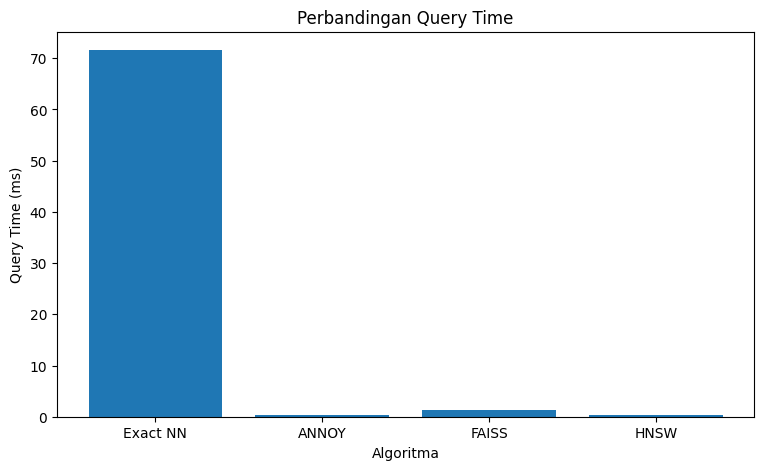

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    hasil['Algoritma'],
    hasil['Query Time (ms)']
)

plt.title('Perbandingan Query Time')
plt.xlabel('Algoritma')
plt.ylabel('Query Time (ms)')

plt.show()